In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.recherche import rechercher
from PIL import Image
from IPython.display import display

def afficher(resultats):
    for rang, r in enumerate(resultats, start=1):
        print(f"\n{rang}. {r['type'].upper()} | page {r['page']} | similarité {r['similarite']}")
        if r["type"] == "image":
            with Image.open(ROOT / r["chemin"]) as img:
                apercu = img.convert("RGB")
                apercu.thumbnail((350, 350))
                display(apercu)
        else:
            print("  ", r["contenu"])

c:\Users\aliel\Downloads\tp3_rag\rag-multimodal-agentique_tp3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
afficher(rechercher(texte="Why are attention scores divided by the square root of d_k?",
                    type_resultat="texte", k=3))


1. TEXTE | page 3 | similarité 0.703
   are all vectors . the output is computed as a weighted sum 3

2. TEXTE | page 4 | similarité 0.692
   , since it can be implemented using highly optimized matrix multiplication code . while for small values of dk the two mechanisms perform similarly , additive attention outperforms dot product attention without scaling for larger values of dk [ 3 ]. we suspect that for large values of dk , the dot products grow large in

3. TEXTE | page 4 | similarité 0.681
   max ( qkt ) v ( 1 ) √ dk the two most commonly used attention functions are additive attention [ 2 ], and dot - product ( multi - plicative ) attention . dot - product attention is identical to our algorithm , except for the scaling factor of √ dk 1 . additive attention



1. IMAGE | page 3 | similarité 0.289


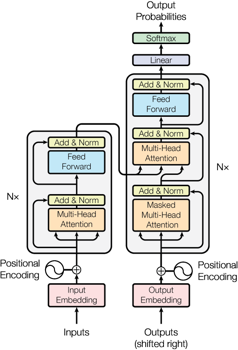


2. IMAGE | page 4 | similarité 0.269


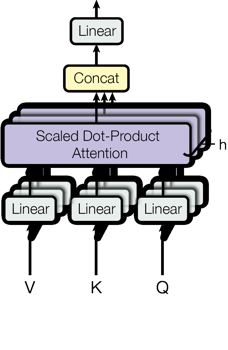


3. IMAGE | page 4 | similarité 0.261


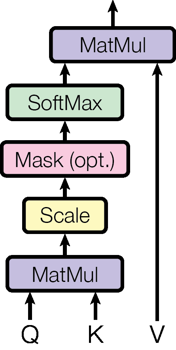

In [3]:
afficher(rechercher(texte="diagram of the Transformer model architecture with encoder and decoder",
                    type_resultat="image", k=3))


1. IMAGE | page 3 | similarité 1.0


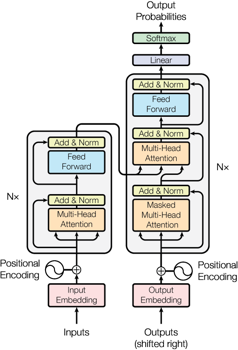


2. IMAGE | page 4 | similarité 0.7


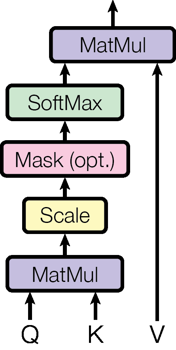


3. IMAGE | page 4 | similarité 0.6


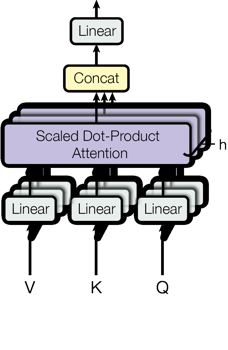

In [4]:
une_image = sorted((ROOT / "resultats_pdf" / "images").iterdir())[0]
afficher(rechercher(image=une_image, type_resultat="image", k=3))

In [5]:
afficher(rechercher(image=une_image, type_resultat="texte", k=3))


1. TEXTE | page 6 | similarité 0.329
   the sequence . to this end , we add " positional encodings " to the input embeddings at the bottoms of the encoder and decoder stacks . the positional encodings have the same dimension dmodel as the embeddings , so that the two can be summed . there are

2. TEXTE | page 3 | similarité 0.313
   . we also modify the self - attention sub - layer in the decoder stack to prevent positions from attending to subsequent positions . this masking , combined with fact that the output embeddings are offset by one position , ensures that the predictions for position i can depend only on the known outputs at positions

3. TEXTE | page 13 | similarité 0.312
   > < pad > figure 3 : an example of the attention mechanism following long - distance dependencies in the encoder self - attention in layer 5 of 6 . many of the attention heads attend to a distant dependency of the verb 'm aking ', completing the phrase 'm aking ... more difficult '. attentions


In [6]:
afficher(rechercher(texte="diagram of the Transformer model architecture", k=6))


1. TEXTE | page 2 | similarité 0.723
   rent network . in this work we propose the transformer , a model architecture eschewing recurrence and instead relying entirely on an attention mechanism to draw global dependencies between input and output . the transformer allows for significantly more parallelization and can reach a new state of the art in translation quality after being

2. TEXTE | page 3 | similarité 0.723
   figure 1 : the transformer - model architecture . the transformer follows this overall architecture using stacked self - attention and point - wise , fully connected layers for both the encoder and decoder , shown in the left and right halves of figure 1 , respectively . 3 . 1 encoder and decoder stacks

3. TEXTE | page 2 | similarité 0.698
   and have been shown to perform well on simple - language question answering and language modeling tasks [ 3 4 ]. to the best of our knowledge , however , the transformer is the first transduction model relying entirely on self - 


1. TEXTE | page 2 | similarité 0.723
   rent network . in this work we propose the transformer , a model architecture eschewing recurrence and instead relying entirely on an attention mechanism to draw global dependencies between input and output . the transformer allows for significantly more parallelization and can reach a new state of the art in translation quality after being

2. TEXTE | page 3 | similarité 0.723
   figure 1 : the transformer - model architecture . the transformer follows this overall architecture using stacked self - attention and point - wise , fully connected layers for both the encoder and decoder , shown in the left and right halves of figure 1 , respectively . 3 . 1 encoder and decoder stacks

3. TEXTE | page 2 | similarité 0.698
   and have been shown to perform well on simple - language question answering and language modeling tasks [ 3 4 ]. to the best of our knowledge , however , the transformer is the first transduction model relying entirely on self - 

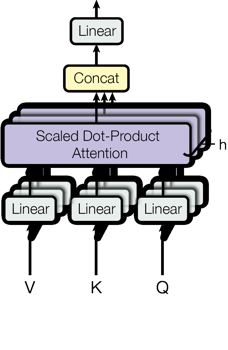


6. IMAGE | page 4 | similarité 0.273


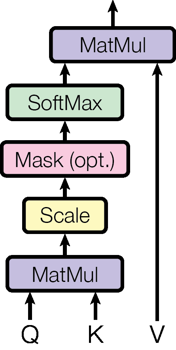

In [7]:
def rechercher_hybride(texte, k_texte=4, k_image=2):
    """Une recherche par modalité, puis on fusionne : les images ont toujours leur place."""
    return (rechercher(texte=texte, type_resultat="texte", k=k_texte)
          + rechercher(texte=texte, type_resultat="image", k=k_image))

afficher(rechercher_hybride("diagram of the Transformer model architecture"))